In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

ROOT = Path.cwd().parent
PROCESSED = ROOT / "data" / "processed"

instagram_df = pd.read_csv(PROCESSED / "instagram_features.csv")
instafake_df = pd.read_csv(PROCESSED / "instafake_features.csv")
cresci_df = pd.read_csv(PROCESSED / "cresci2017_features.csv")

print("Instagram:", instagram_df.shape)
print("InstaFake:", instafake_df.shape)
print("Cresci:", cresci_df.shape)

Instagram: (696, 10)
InstaFake: (1194, 10)
Cresci: (4465, 11)


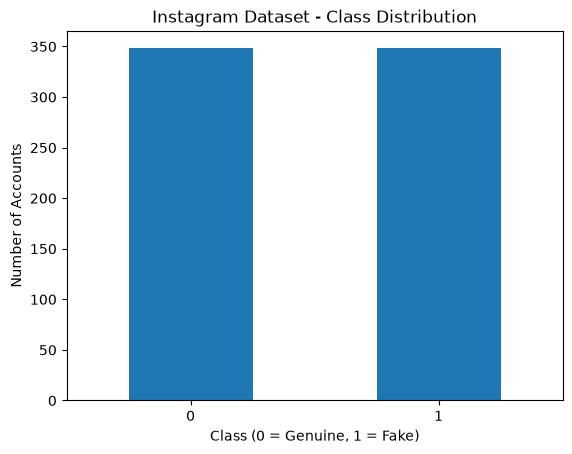

fake
0    348
1    348
Name: count, dtype: int64
fake
0    50.0
1    50.0
Name: proportion, dtype: float64


In [3]:
instagram_df["fake"].value_counts().plot(kind="bar")

plt.title("Instagram Dataset - Class Distribution")
plt.xlabel("Class (0 = Genuine, 1 = Fake)")
plt.ylabel("Number of Accounts")
plt.xticks(rotation=0)
plt.show()
print(instagram_df["fake"].value_counts())
print(instagram_df["fake"].value_counts(normalize=True) * 100)

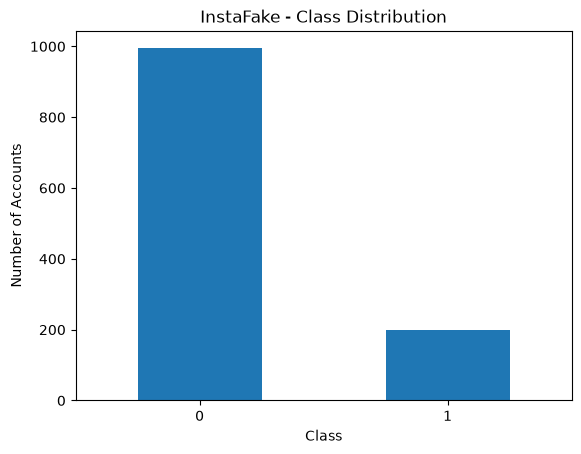

fake
0    994
1    200
Name: count, dtype: int64


In [4]:
instafake_df["fake"].value_counts().plot(kind="bar")

plt.title("InstaFake - Class Distribution")
plt.xlabel("Class")
plt.ylabel("Number of Accounts")
plt.xticks(rotation=0)
plt.show()

print(instafake_df["fake"].value_counts())

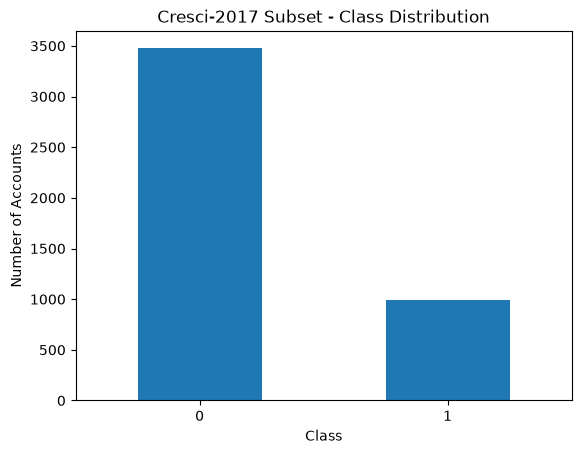

fake
0    3474
1     991
Name: count, dtype: int64


In [5]:
cresci_df["fake"].value_counts().plot(kind="bar")

plt.title("Cresci-2017 Subset - Class Distribution")
plt.xlabel("Class")
plt.ylabel("Number of Accounts")
plt.xticks(rotation=0)
plt.show()

print(cresci_df["fake"].value_counts())

In [7]:
FEATURES = [
    "followers",
    "following",
    "posts",
    "bio_length",
    "has_profile_picture",
    "is_private",
    "username_digit_ratio",
    "follower_following_ratio",
    "profile_completeness"
]
instagram_df.groupby("fake")[FEATURES].mean().T

fake,0,1
followers,158157.186782,142.623563
following,712.873563,397.298851
posts,197.919540,8.568966
bio_length,41.882184,4.942529
has_profile_picture,0.994253,0.428161
is_private,0.433908,0.304598
username_digit_ratio,0.041810,0.291408
follower_following_ratio,6011.158768,1.506929
profile_completeness,1.000000,1.000000


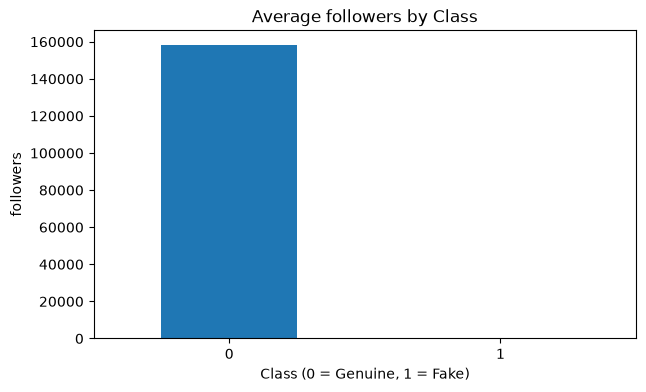

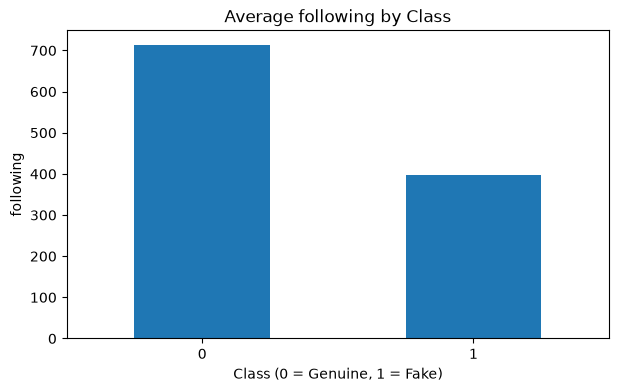

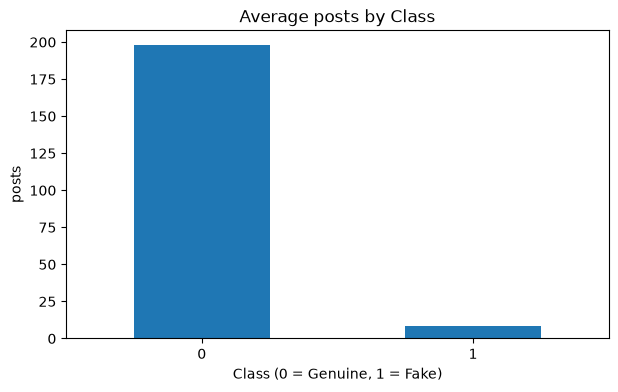

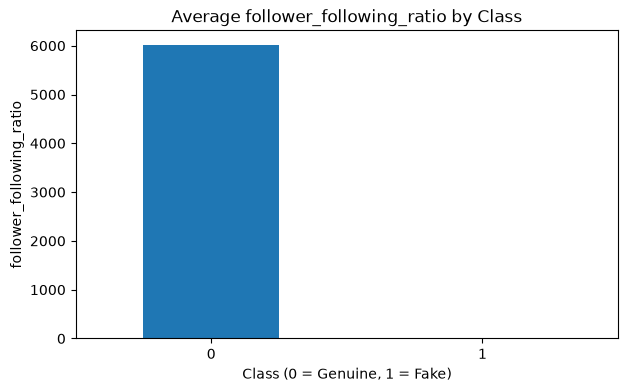

In [8]:
plot_features = [
    "followers",
    "following",
    "posts",
    "follower_following_ratio"
]

for feature in plot_features:

    plt.figure(figsize=(7, 4))

    instagram_df.groupby("fake")[feature].mean().plot(kind="bar")

    plt.title(f"Average {feature} by Class")
    plt.xlabel("Class (0 = Genuine, 1 = Fake)")
    plt.ylabel(feature)
    plt.xticks(rotation=0)

    plt.show()

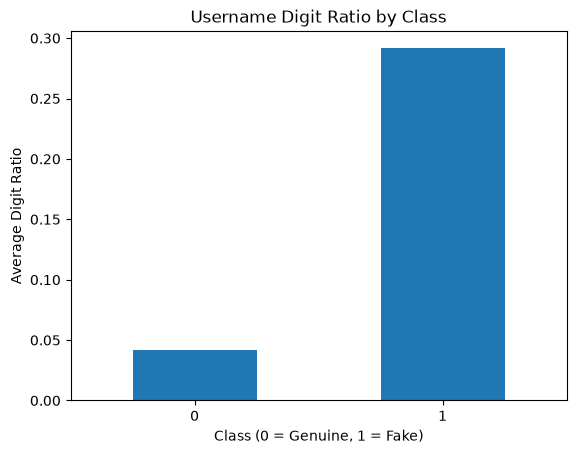

In [9]:
instagram_df.groupby("fake")["username_digit_ratio"].mean().plot(
    kind="bar"
)

plt.title("Username Digit Ratio by Class")
plt.xlabel("Class (0 = Genuine, 1 = Fake)")
plt.ylabel("Average Digit Ratio")
plt.xticks(rotation=0)
plt.show()

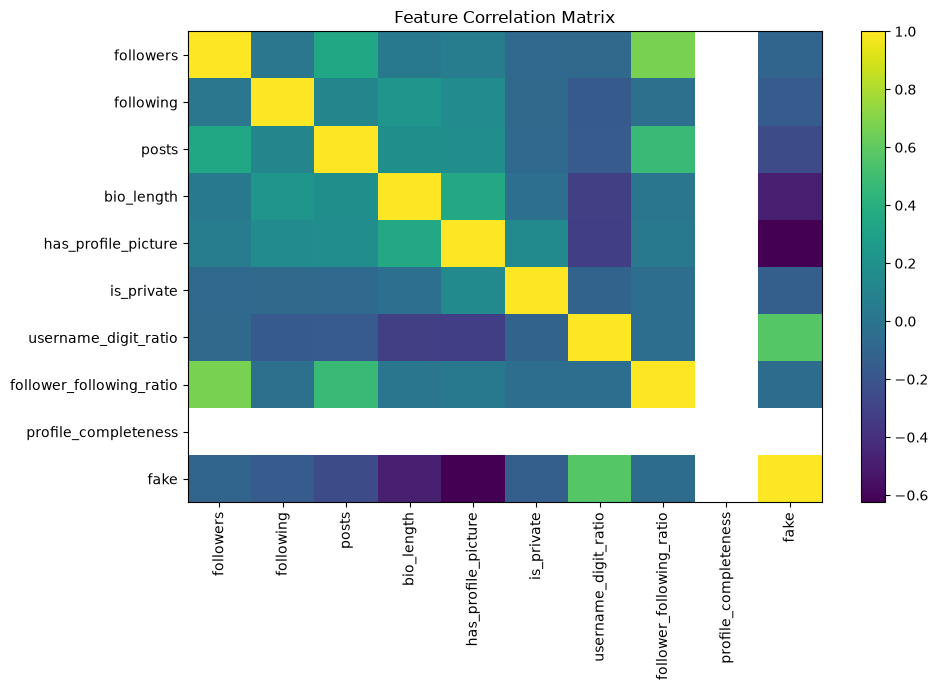

In [10]:
corr = instagram_df[FEATURES + ["fake"]].corr()

plt.figure(figsize=(10, 7))

plt.imshow(corr, aspect="auto")
plt.colorbar()

plt.xticks(
    range(len(corr.columns)),
    corr.columns,
    rotation=90
)

plt.yticks(
    range(len(corr.columns)),
    corr.columns
)

plt.title("Feature Correlation Matrix")

plt.tight_layout()
plt.show()

In [12]:
instagram_df[
    [
        "followers",
        "following",
        "posts",
        "follower_following_ratio"
    ]
].describe().T
for feature in [
    "followers",
    "following",
    "posts",
    "follower_following_ratio"
]:
    print(
        f"{feature}:",
        "max =", instagram_df[feature].max(),
        "| median =", instagram_df[feature].median()
    )

followers: max = 15338538 | median = 165.5
following: max = 7500 | median = 252.0
posts: max = 7389 | median = 9.0
follower_following_ratio: max = 1549714.875 | median = 0.7854739980475449


In [13]:
print("Missing values:")
print(instagram_df[FEATURES + ["fake"]].isna().sum())

print("\nInfinite values:")
print(
    np.isinf(
        instagram_df[FEATURES].select_dtypes(include=np.number)
    ).sum()
)

Missing values:
followers                   0
following                   0
posts                       0
bio_length                  0
has_profile_picture         0
is_private                  0
username_digit_ratio        0
follower_following_ratio    0
profile_completeness        0
fake                        0
dtype: int64

Infinite values:
followers                   0
following                   0
posts                       0
bio_length                  0
has_profile_picture         0
is_private                  0
username_digit_ratio        0
follower_following_ratio    0
profile_completeness        0
dtype: int64
